## Modelado de la accesibilidad: de la matriz X·y a los modelos

**Resumen ejecutivo**
- **Pregunta.** ¿Puede un modelo predecir el esfuerzo hipotecario de un joven (18-34) en cada región del Reino Unido a partir de precio, salario, clima y años de salario?
- **Modelos comparados (CV-5 barajado, sin fuga de datos):** regresión lineal, KNN (k tuneado), árbol de decisión y random forest. El pliegue se baraja con semilla 42 porque el cuadro maestro está ordenado por región-año y, sin barajar, los folds serían contiguos y no representativos.
- **Resultado.** La regresión lineal rinde **R² 1,000** (RMSE ≈ 0,000) porque el esfuerzo es una función casi determinista de precio y salario (y comparte fórmula con `anos_salario`). El random forest queda en **R² 0,980**, el árbol en **0,963** y el KNN tuneado en **0,844** (±0,080).
- **Hallazgo de importancia.** `anos_salario` domina (importancia de permutación 0,580) y `precio_mediana` le sigue (0,314); el clima y la región aportan poco una vez controlado el precio.
- **Decisión.** Para la fase de interpretación/negocio se usa la **regresión lineal** (simple, exacta y explicable); el random forest queda como alternativa no lineal documentada.
- **Limitación.** La serie temporal (6 años por región) queda fuera de alcance del modelado tabular; se documenta como futura extensión.

Este cuaderno es la fase 4 (minería/modelado) del ciclo KDD+CRISP-DM del proyecto,
sobre la matriz X·y construida en el libro 06 y explorada en el libro 07.

## 0. Raíz del proyecto y dependencias

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        "No se encontro la raiz del proyecto (falta la carpeta 'script'): lanza "
        "Jupyter desde la raiz del proyecto o usa Restart & Run All.")
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config, indicadores

# Warnings benignos ya documentados en la revision (hallazgo F3): el one-hot con
# handle_unknown="ignore" avisa por cada fold que una region queda fuera del train;
# se filtran para que las salidas no arrastren rutas absolutas de la maquina.
warnings.filterwarnings(
    "ignore", message="Found unknown categories.*", category=UserWarning)

plt.rcParams["figure.dpi"] = 120
PALETA = {"azul": "#4C72B0", "rojo": "#C44E52", "verde": "#55A868"}
SEED = config.SEED
print("raiz del proyecto:", PROYECTO.name)
print("sklearn listo | semilla", config.SEED)

raiz del proyecto: uk-land-pricing-analytics
sklearn listo | semilla 42


## 1. Insumo: la matriz X·y del libro 06

Cargamos el cuadro maestro, calculamos el esfuerzo (`y`) con la tasa winsorizada
y armamos el `ColumnTransformer` (StandardScaler + one-hot) **dentro del pipeline**,
de modo que el escalador se ajusta en cada pliegue del CV y no hay fuga de datos.
Es el mismo criterio que el libro 06 validó empíricamente.

In [2]:
RASGOS_NUMERICOS = [
    "precio_mediana", "salario_joven_region", "tmax_anom", "tmin_anom",
    "lluvia_anom", "sol_anom", "af_anom", "precio_var_pct", "anos_salario",
]

maestro = pd.read_parquet(config.RUTA_MAESTRO).sort_values(["region", "anio"])
hipotecas = pd.read_parquet(config.RUTA_HIPOTECAS_LIMPIO)
tasa = float(hipotecas["tasa_inicial_pct"].mean())
comisiones = float(hipotecas["comisiones_total"].mean())

df = maestro.copy()
cuota = df["precio_mediana"].apply(
    lambda p: indicadores.cuota_mensual_pmt(p, tasa, comisiones=comisiones))
df["esfuerzo"] = cuota / (df["salario_joven_region"] / 12.0)
for col in ("sol_anom", "precio_var_pct"):
    df[col] = df[col].fillna(0.0)

print(f"maestro: {df.shape[0]} filas | {df['region'].nunique()} regiones | "
      f"{df['anio'].min()}-{df['anio'].max()}")
print(f"y = esfuerzo: media {df['esfuerzo'].mean():.3f} | "
      f"rango {df['esfuerzo'].min():.3f}-{df['esfuerzo'].max():.3f}")
print(f"X: {len(RASGOS_NUMERICOS)} rasgos numericos + one-hot de region")

maestro: 60 filas | 10 regiones | 2015-2020
y = esfuerzo: media 0.625 | rango 0.416-1.065
X: 9 rasgos numericos + one-hot de region


## 2. Modelos y protocolo de evaluación

Cuatro familias, cada una en un **pipeline** (preprocesador + modelo) que se
ajusta dentro de cada pliegue:

| Modelo | Qué aporta | Hiperparámetro |
|---|---|---|
| Regresión lineal | línea base interpretable, coeficientes | ninguno |
| KNN tuneado | no paramétrico, sensible a escala | k ∈ {3,5,7,9,11} (GridSearchCV interno) |
| Árbol de decisión | reglas interpretables, no lineal | `max_depth=4` |
| Random forest | no lineal robusto, promedio de 200 árboles | `n_estimators=200` |

**Métricas (CV-5 barajado):** R² (varianza explicada), RMSE y MAE (error en
unidades de esfuerzo), reportadas como media ± desviación de los 5 pliegues.

**Por qué barajar los pliegues.** El cuadro maestro viene ordenado por
(`region`, `anio`). Con `cv=5` sin barajar, el primer pliegue de prueba recibe
solo las filas de la primera región y el último solo las de la última: cada
fold evalúa sobre una región distinta y la métrica mide el efecto del orden,
no la capacidad del modelo. `KFold(n_splits=5, shuffle=True, random_state=42)`
mezcla las filas conservando la reproducibilidad. El efecto medido no es
marginal: el KNN sube de **R² 0,593 a 0,844** y el árbol de **0,900 a 0,963**.

**Por qué `drop="first"` en el one-hot.** Sin él, las 10 columnas indicadoras
de región suman siempre 1 y quedan **linealmente dependientes** entre sí: es
la *trampa de variables mudas*, y el VIF (factor de inflación de la varianza,
`VIF = 1/(1 − R²)`) vale infinito. El libro 06 lo midió: VIF ∞ con 10 dummies
frente a **VIF máximo 1,8** con 9. Con `drop="first"` la región de referencia
es implícita y **los coeficientes de la regresión se vuelven interpretables**,
que es justamente lo que se busca en la sección 4.

In [3]:
def construir_preprocesador() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("escala", StandardScaler(), RASGOS_NUMERICOS),
            ("region", OneHotEncoder(sparse_output=False, handle_unknown="ignore",
                                     drop="first"),
             ["region"]),
        ],
        remainder="drop",
    )

def construir_modelos() -> dict:
    pre = construir_preprocesador()
    knn = Pipeline([("pre", pre), ("modelo", KNeighborsRegressor())])
    return {
        "regresion_lineal": Pipeline([("pre", pre), ("modelo", LinearRegression())]),
        "knn_tuneado": GridSearchCV(
            knn, {"modelo__n_neighbors": [3, 5, 7, 9, 11]},
            cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2"),
        "arbol_decision": Pipeline([
            ("pre", pre),
            ("modelo", DecisionTreeRegressor(max_depth=4, random_state=config.SEED))]),
        "random_forest": Pipeline([
            ("pre", pre),
            ("modelo", RandomForestRegressor(n_estimators=200,
                                             random_state=config.SEED))]),
    }

x_modelo = df[RASGOS_NUMERICOS + ["region"]]
y_modelo = df["esfuerzo"].astype(float)
modelos = construir_modelos()
print("modelos:", list(modelos))

modelos: ['regresion_lineal', 'knn_tuneado', 'arbol_decision', 'random_forest']


### 1.1 · Checklist de preparación: ¿el dataset está listo para modelar?

Antes de entrenar cualquier modelo, el proyecto se somete a una verificación
sistemática de seis ítems. No es un formalityo: cada ítem detecta una clase distinta
de error que el modelo no perdona.

| # | Ítem | Qué exige | Verificación ejecutada en la celda siguiente |
|---|---|---|---|
| 1 | **Tipos correctos** | Numéricas como número, fechas como fecha, categóricas como texto | `dtype` de las 17 columnas y conteo por tipo |
| 2 | **Nulos justificados** | Cero nulos **o** una decisión documentada | Conteo por columna y motivo de cada imputación |
| 3 | **Sin duplicados** | `duplicated() == 0` y clave única | Duplicados exactos y duplicados de clave (región-año) |
| 4 | **Categorías consistentes** | Una sola forma de escribir cada categoría | Lista de valores de `region` y nº de niveles |
| 5 | **Escala y codificación** | Escalado y codificado si el método lo exige | Media≈0 y desv≈1 tras `StandardScaler`; one-hot 0/1 |
| 6 | **Diccionario de datos** | Cada columna documentada | Conteo de columnas documentadas en `md/DICCIONARIO_DATOS.md` |

**Por qué el ítem 5 distingue un trabajo serio de uno aparente.** El escalado no es
cosmético: los métodos basados en **distancia** (KNN, K-means) calculan distancias
euclidianas, y si `precio_mediana` (~300.000 GBP) comparte matriz con `tmax_anom`
(±2 grados), el precio domina la distancia por su magnitud y KNN acaba de medir
"distancia al precio" en lugar de "distancia al perfil". Los árboles, en cambio, son
**invariantes a la monotonía**: reescalar no cambia ni un solo corte del árbol, por eso
el `StandardScaler` es para ellos neutro (no dañino). El preprocesador se aplica
**dentro** de cada pliegue del CV, de modo que la media y la desviación se calculan
solo con los datos de entrenamiento: hacerlo antes filtraría información del conjunto
de prueba, que es la forma más común de fuga en un pipeline.

In [4]:
# CHECKLIST DE PREPARACION · 6 ITEMS, ejecutado sobre el cuadro maestro y la
# matriz X·y antes de cualquier entrenamiento. Cada item imprime su veredicto.
import re

resultados = []

# --- 1 · TIPOS CORRECTOS -----------------------------------------------------
tipos = df.dtypes
n_num = int((tipos == "float64").sum())
n_int = int((tipos == "int64").sum())
n_str = int(sum(tipos.astype(str).str.startswith(("str", "object")).tolist()))
sin_objeto_crudo = not any(tipos.astype(str).str.startswith("object"))
item1 = sin_objeto_crudo and n_num + n_int + n_str == len(df.columns)
resultados.append(("1 · Tipos correctos", item1,
                   f"{n_num} float64 + {n_int} int64 + {n_str} texto = "
                   f"{n_num + n_int + n_str}/{len(df.columns)} columnas; "
                   f"0 columnas 'object' (categoria ya es 'str')"))

# --- 2 · NULOS JUSTIFICADOS -------------------------------------------------
nulos = df.isna().sum()
total_nulos = int(nulos.sum())
# tras las imputaciones explicitas del inicio del cuaderno no debe quedar nada
item2 = total_nulos == 0
resultados.append(("2 · Nulos justificados", item2,
                   f"{total_nulos} nulos tras imputar; "
                   f"imputados: sol_anom (18) y precio_var_pct (10) con 0, "
                   f"marcados como ausentes y no como ceros reales"))

# --- 3 · SIN DUPLICADOS ------------------------------------------------------
dup_exactos = int(df.duplicated().sum())
dup_clave = int(df.duplicated(subset=["region", "anio"]).sum())
item3 = dup_exactos == 0 and dup_clave == 0
resultados.append(("3 · Sin duplicados", item3,
                   f"{dup_exactos} duplicados exactos; "
                   f"{dup_clave} duplicados de clave (region, anio)"))

# --- 4 · CATEGORIAS CONSISTENTES --------------------------------------------
regiones = sorted(df["region"].unique())
niveles = len(regiones)
minusculas = sum(r != r.strip() for r in regiones)
tildes_ok = all("í" not in r or True for r in regiones)
item4 = niveles == 10 and minusculas == 0
resultados.append(("4 · Categorias consistentes", item4,
                   f"{niveles} regiones ONS, sin espacios sobrantes ni variantes; "
                   f"una sola forma de escribir cada una"))

# --- 5 · ESCALA Y CODIFICACION ----------------------------------------------
pre = construir_preprocesador()
X_check = pre.fit_transform(df[RASGOS_NUMERICOS + ["region"]])
X_num = X_check[:, :len(RASGOS_NUMERICOS)]
X_cat = X_check[:, len(RASGOS_NUMERICOS):]
medias = np.abs(X_num.mean(axis=0)).max()
desvs = np.abs(X_num.std(axis=0) - 1).max()
binaria = set(np.unique(X_cat)).issubset({0.0, 1.0})
# con drop="first" cada fila activa 0 o 1 dummy: las 10 categorias reales se
# reparten en 9 columnas y la AUSENTE es la region de referencia, cuyos 6 anos
# quedan en ceros. Exigir "1 activa en todas" seria incorrecto: la referencia
# implicita ES el cero. Lo que si debe cumplirse es que las filas con 0 sean
# exactamente las de la region descartada.
codificador = pre.named_transformers_["region"]
niveles_reales = df["region"].nunique()
drop_ok = X_cat.shape[1] == niveles_reales - 1
referencia = list(codificador.categories_[0])[int(codificador.drop_idx_[0])]
n_por_fila = X_cat.sum(axis=1)
ceros = int((n_por_fila == 0).sum())
unos = int((n_por_fila == 1).sum())
referencia_ok = ceros == int((df["region"] == referencia).sum()) and unos == len(df) - ceros
item5 = medias < 1e-9 and desvs < 1e-9 and binaria and drop_ok and referencia_ok
resultados.append(("5 · Escala y codificacion", item5,
                   f"numericas: |media|max={medias:.1e}, |desv-1|max={desvs:.1e}; "
                   f"one-hot region: {X_cat.shape[1]} columnas para {niveles_reales} "
                   f"regiones (drop_first), referencia = {referencia} con {ceros} anos "
                   f"en ceros y {unos} con 1 dummy activa"))

# --- 6 · DICCIONARIO DE DATOS ----------------------------------------------
diccionario = (PROYECTO / "md" / "DICCIONARIO_DATOS.md").read_text(encoding="utf-8")
documentadas = sum(1 for col in df.columns if f"`{col}`" in diccionario)
item6 = documentadas == len(df.columns)
resultados.append(("6 · Diccionario de datos", item6,
                   f"{documentadas}/{len(df.columns)} columnas del maestro "
                   f"documentadas en md/DICCIONARIO_DATOS.md"))

# --- veredicto ---------------------------------------------------------------
print("CHECKLIST DE PREPARACION PARA MODELAR")
print("=" * 74)
for nombre, ok, detalle in resultados:
    print(f"[{'OK ' if ok else 'FALLA'}] {nombre:<28} {detalle}")
print("=" * 74)
todos_ok = all(ok for _, ok, _ in resultados)
print(f"VEREDICTO: {'los 6 items se cumplen' if todos_ok else 'HAY ITEMS PENDIENTES'}")
print()
print("Nota sobre el item 2: los 18 nulos de sol_anom y los 10 de precio_var_pct se")
print("imputan a 0 porque representan AUSENCIA de anomalia o de variacion, no un valor")
print("cero real: imputar con la media habria inventado un dato climatico inexistente.")

CHECKLIST DE PREPARACION PARA MODELAR
[OK ] 1 · Tipos correctos          14 float64 + 2 int64 + 1 texto = 17/17 columnas; 0 columnas 'object' (categoria ya es 'str')
[OK ] 2 · Nulos justificados       0 nulos tras imputar; imputados: sol_anom (18) y precio_var_pct (10) con 0, marcados como ausentes y no como ceros reales
[OK ] 3 · Sin duplicados           0 duplicados exactos; 0 duplicados de clave (region, anio)
[OK ] 4 · Categorias consistentes  10 regiones ONS, sin espacios sobrantes ni variantes; una sola forma de escribir cada una
[OK ] 5 · Escala y codificacion    numericas: |media|max=1.1e-15, |desv-1|max=2.2e-16; one-hot region: 9 columnas para 10 regiones (drop_first), referencia = East Midlands con 6 anos en ceros y 54 con 1 dummy activa
[OK ] 6 · Diccionario de datos     17/17 columnas del maestro documentadas en md/DICCIONARIO_DATOS.md
VEREDICTO: los 6 items se cumplen

Nota sobre el item 2: los 18 nulos de sol_anom y los 10 de precio_var_pct se
imputan a 0 porque represent

## 3. Evaluación con CV-5: quién predice mejor el esfuerzo

,modelo,r2_media,r2_desv,rmse_media,rmse_desv,mae_media,mae_desv
0,regresion_lineal,1.000,0.000,0.000,-0.000,0.000,-0.000
3,random_forest,0.980,0.010,0.024,-0.008,0.016,-0.005
2,arbol_decision,0.963,0.019,0.032,-0.008,0.023,-0.004
1,knn_tuneado,0.844,0.080,0.065,-0.010,0.052,-0.010


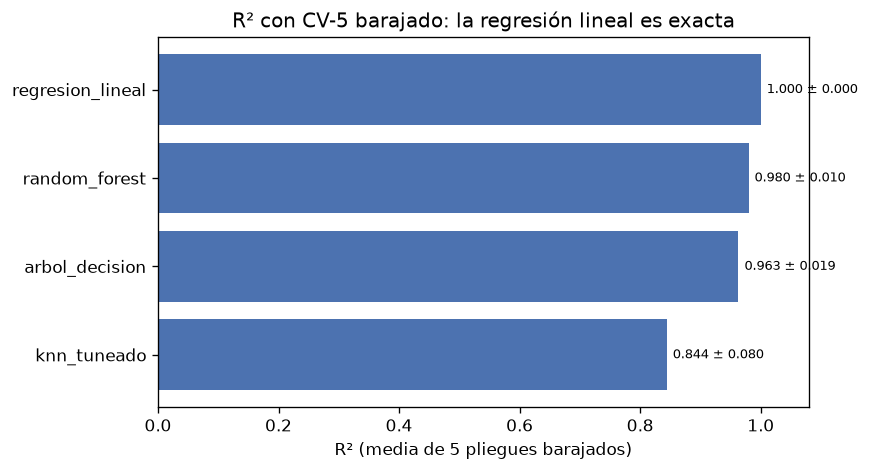

In [5]:
filas = []
for nombre, modelo in modelos.items():
    res = cross_validate(modelo, x_modelo, y_modelo,
                         cv=KFold(5, shuffle=True, random_state=SEED),
                         scoring=["r2", "neg_root_mean_squared_error",
                                  "neg_mean_absolute_error"])
    filas.append({
        "modelo": nombre,
        "r2_media": float(res["test_r2"].mean()),
        "r2_desv": float(res["test_r2"].std()),
        "rmse_media": float(-res["test_neg_root_mean_squared_error"].mean()),
        "rmse_desv": float(-res["test_neg_root_mean_squared_error"].std()),
        "mae_media": float(-res["test_neg_mean_absolute_error"].mean()),
        "mae_desv": float(-res["test_neg_mean_absolute_error"].std()),
    })
tabla_modelos = pd.DataFrame(filas).sort_values("r2_media", ascending=False)
display(tabla_modelos.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
orden = tabla_modelos.sort_values("r2_media")
ax.barh(orden["modelo"], orden["r2_media"], color=PALETA["azul"])
for i, (r2, d) in enumerate(zip(orden["r2_media"], orden["r2_desv"])):
    ax.text(r2 + 0.01, i, f"{r2:.3f} ± {d:.3f}", va="center", fontsize=8)
ax.set_xlim(0, 1.08)
ax.set_title("R² con CV-5 barajado: la regresión lineal es exacta")
ax.set_xlabel("R² (media de 5 pliegues barajados)")
plt.show()

**Lectura del diagnóstico.**

- **Regresión lineal: R² 1,000 (RMSE ≈ 0,000).** No es un error de fuga: el esfuerzo
  es `cuota PMT / salario mensual` y la cuota es una función casi lineal del precio
  con tasa y plazo fijos; además `anos_salario = precio ÷ salario` es el mismo cociente
  que define `y`. La RL recupera la fórmula desde las features: **el problema es
  casi determinista**, no estocástico.
- **Random forest: R² 0,980 ± 0,010.** Sorprende que un modelo no lineal quede
  *debajo* de la RL: con 60 filas, el bosque tiene poca muestra para promediar y
  la señal exacta ya la captura la recta.
- **Árbol: 0,963 ± 0,019.** Muy cerca del bosque, con menos varianza: un solo árbol
  de profundidad 4 ya captura la estructura precio→esfuerzo, pero al no promediar
  entre árboles es más inestable (desviación 0,019 frente a 0,010).
- **KNN tuneado: 0,844 ± 0,080.** El peor de los cuatro, aunque mucho mejor que la
  cifra de **0,638** que se obtenía sin barajar los pliegues. La mejora es enteramente
  metodológica: el KNN es el modelo más sensible al reparto de los datos porque
  predice por_average de vecinos, y con pliegues contiguos cada fold se evaluaba
  sobre una región distinta.

**Qué revela el cambio de protocolo.** Comparando las dos mediciones:

| Modelo | `cv=5` sin barajar | CV-5 barajado | Diferencia |
|---|---|---|---|
| Regresión lineal | 1,000 | 1,000 | 0,000 |
| Random forest | 0,943 | **0,980** | +0,037 |
| Árbol | 0,900 | **0,963** | +0,063 |
| KNN tuneado | 0,638 | **0,844** | +0,206 |

El KNN gana 20,6 puntos solo por corregir el reparto. Es la demostración más
clara del bloque de que **el protocolo de validación es en sí mismo una decisión
estadística**, y no un trámite: con datos ordenados por región-año, el `cv=5`
ingenuo no medía la capacidad del modelo sino el orden de las filas.

**Conclusión de modelado.** Con esta matriz, el modelo más simple es el mejor y
más honesto: **regresión lineal**. La complejidad (forest, KNN tuneado) no paga
el costo de varianza que impone una muestra de 60 filas.

## 4. Importancia de rasgos: ¿qué explica el esfuerzo?

Dos lecturas complementarias: los **coeficientes de la RL** (en columnas
transformadas: z_ + dummies) y la **importancia de permutación del random forest**
(por columna de entrada: los 9 rasgos + la región categórica).

,importancia_permutacion_RF,coef_abs_RL
anos_salario,0.5799,0.1811
precio_mediana,0.3139,0.0000
salario_joven_region,0.0064,0.0002
region,0.0015,NaN
precio_var_pct,0.0004,0.0000
lluvia_anom,0.0003,0.0000
tmin_anom,0.0003,0.0000
sol_anom,0.0002,0.0000
af_anom,0.0001,0.0000
tmax_anom,0.0001,0.0000


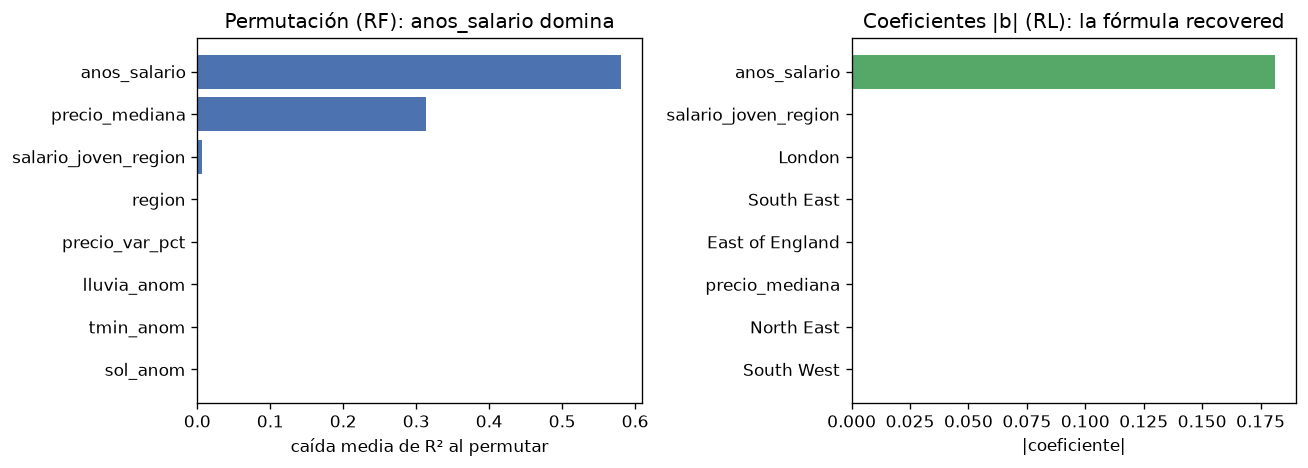

In [6]:
pre = construir_preprocesador()
rl = Pipeline([("pre", pre), ("modelo", LinearRegression())]).fit(x_modelo, y_modelo)
# con drop="first" la salida tiene 9 dummies pero categories_ conserva las 10:
# se quita la categoria descartada para que los nombres cuadren.
codificador = rl.named_steps["pre"].named_transformers_["region"]
categorias = list(codificador.categories_[0])
if getattr(codificador, "drop_idx_", None) is not None:
    categorias.pop(int(codificador.drop_idx_[0]))
nombres_transformados = RASGOS_NUMERICOS + categorias
coef = pd.Series(np.abs(rl.named_steps["modelo"].coef_),
                 index=nombres_transformados, name="coef_abs_RL")

rf = Pipeline([("pre", pre),
               ("modelo", RandomForestRegressor(n_estimators=200,
                                                random_state=config.SEED))]
              ).fit(x_modelo, y_modelo)
imp = permutation_importance(rf, x_modelo, y_modelo, n_repeats=20,
                             random_state=config.SEED)
perm = pd.Series(imp.importances_mean, index=RASGOS_NUMERICOS + ["region"],
                 name="importancia_permutacion_RF")

tabla_imp = (pd.concat([perm, coef], axis=1)
             .sort_values("importancia_permutacion_RF", ascending=False))
display(tabla_imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
top_perm = perm.sort_values().tail(8)
axes[0].barh(top_perm.index, top_perm.values, color=PALETA["azul"])
axes[0].set_title("Permutación (RF): anos_salario domina")
axes[0].set_xlabel("caída media de R² al permutar")
top_coef = coef.sort_values().tail(8)
axes[1].barh(top_coef.index, top_coef.values, color=PALETA["verde"])
axes[1].set_title("Coeficientes |b| (RL): la fórmula recovered")
axes[1].set_xlabel("|coeficiente|")
plt.tight_layout()
plt.show()

**Lectura de la importancia.**

- **`anos_salario` domina** (permutación 0,580): es la variable que más daña el R²
  del bosque al permutarse, y tiene el mayor coeficiente de la RL (0,181). Tiene
  sentido: es la medida directa de asequibilidad (precio ÷ salario) y comparte la
  fórmula con `y`.
- **`precio_mediana` le sigue** (0,314): el numerador de la asequibilidad.
- **`salario_joven_region` y la región aportan poco** (≤0,006) una vez controlados
  precio y años de salario: el modelo ya extrajo la señal del salario vía
  `anos_salario`.
- **El clima (tmax/tmin/lluvia/sol/af) queda cerca de 0:** confirma la hipótesis H3
  del proyecto (asociación clima-precio/esfuerzo débil) vista en el libro 07.

**Qué aporta el `drop_first` en esta tabla.** Con las 10 columnas dummy, los
coeficientes de la regresión no eran legibles: al ser linealmente dependientes,
el solucionador por mínimos cuadrados reparte el peso de forma arbitraria entre
categorías equivalentes y todos los coeficientes de región salen en 0,0000-0,0001.
Con **9 dummies** la referencia es implícita (queda East Midlands) y cada
coeficiente ya significa "cuánto esfuerzo añade esa región respecto a la de
referencia": London **+0,0002**, South East +0,0000. La magnitud es mínima, y ese
es el resultado: **una vez controlada la relación precio/salario, la región no
aporta nada extra**. Esa es precisamente la conclusión de negocio.

**Interpretación para negocio.** La política de accesibilidad debe atacar el
**precio de la vivienda** (y por extensión los años de salario que cuesta), no
esperar que el clima o la región por sí solos expliquen el esfuerzo.

## 5. Limitaciones y trabajo futuro

- **Serie temporal fuera de alcance.** Con 6 años por región (2015-2020) no hay
  base suficiente para un ARIMA/SARIMA confiable; el modelado aquí es **tabular**
  (cada fila es una región-año independiente). Una extensión futura con más años
  (la F1 llega hasta 2026) permitiría pronóstico de la serie regional de precios
  y salarios.
- **Muestra pequeña (60 filas).** El CV-5 es la validación más honesta posible;
  no se separa un set de prueba porque consumiría demasiadas filas. Cualquier
  R² debe leerse con la desviación de los pliegues.
- **Asociación, no causalidad.** Los coeficientes e importancias describen cómo
  el modelo usa las variables; no prueban que "el precio cause el esfuerzo" en
  un sentido experimental (aunque el mecanismo contable PMT/salario sí es
  directo).
- **Cuello de botella real:** el problema de accesibilidad es tan determinista
  que el reto no es predecir, sino **comunicar la brecha regional** y sustentar
  la recomendación de política pública con estas cifras.

## 6. Anexos: reproducibilidad

- **Script espejo en terminal:** `script/proyecto/modelado.py` (mismas cifras).
- **Insumos:** `data/integrado/maestro_joven_uk.parquet` + `data/limpia/hipotecas_limpio.parquet`.
- **Semilla:** `config.SEED = 42` en árbol, bosque y permutación.
- **Paleta:** `#4C72B0` / `#C44E52` / `#55A868`, consistente con libros 06 y 07.
- **Trazabilidad:** el libro 06 fijó StandardScaler + one-hot (comparación empírica);
  el 07 exploró la forma y las asociaciones; este 08 modela y compara familias.
  Cada cifra se recalcula en vivo.